In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)
df = iris.frame

print("Dataset shape:", df.shape)
print(df.head())

Dataset shape: (150, 5)
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target  
0       0  
1       0  
2       0  
3       0  
4       0  


In [2]:
# Dataset information
print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nSpecies distribution:")
print(df["target"].value_counts().sort_index())

print("\nStatistical summary:")
print(df.describe())

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB

Missing values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64

Species distribution:
target
0    50
1    50
2    50
Name: count, dtype: int64

Statistical summary:
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765

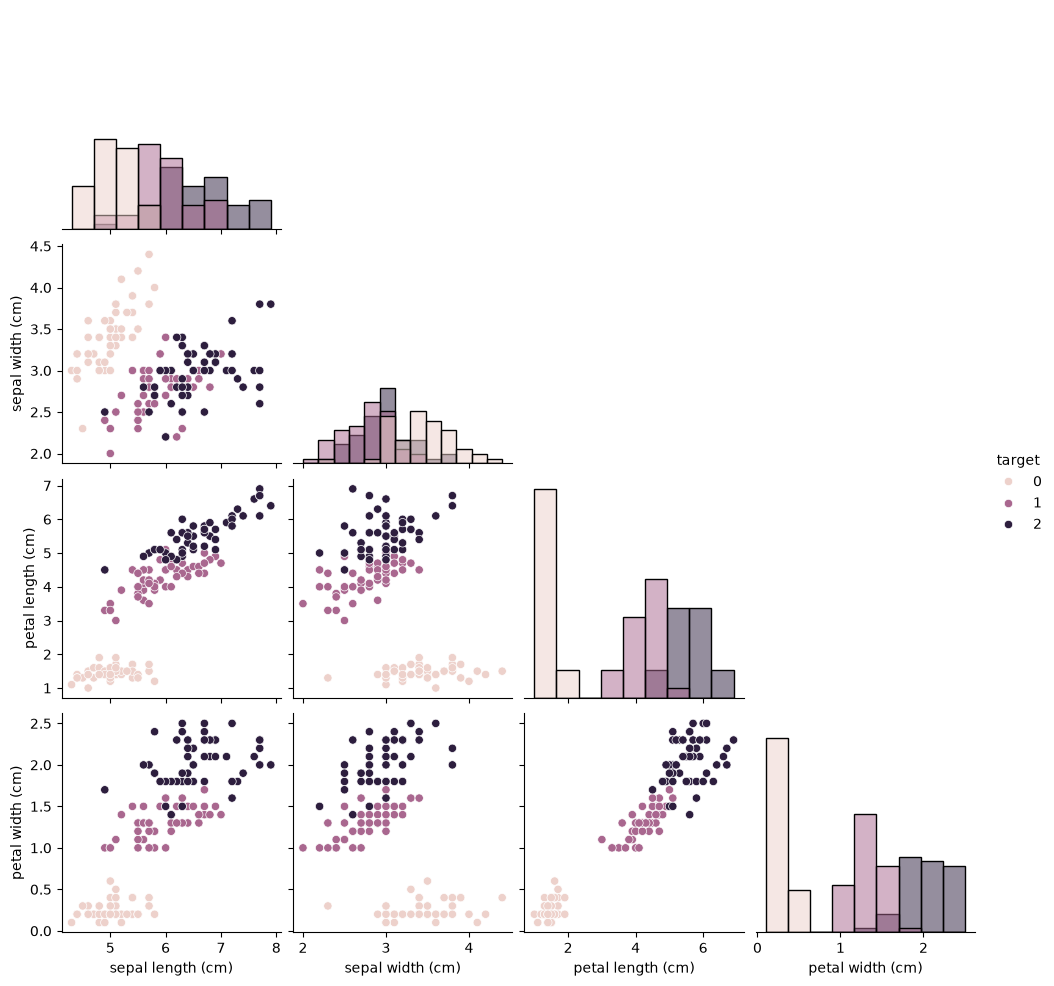

In [3]:
# Pairwise feature relationships
sns.pairplot(
    df,
    hue="target",
    diag_kind="hist",
    corner=True
)

plt.show()

In [4]:

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
from IPython.display import display as ipy_display

# Separate features and target
X = df.drop(columns="target")
y = df["target"]

# Split before training or model selection
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

# Compare three classification models
models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000)
    ),
    "K-Nearest Neighbors": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    ),
    "Support Vector Machine": make_pipeline(
        StandardScaler(),
        SVC()
    )
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    accuracy = accuracy_score(y_test, predictions)

    results.append({
        "Model": name,
        "Accuracy": accuracy
    })

    print(f"\n{name}: {accuracy:.2%}")
    print(classification_report(
        y_test,
        predictions,
        target_names=[
            "Setosa", "Versicolor", "Virginica"
        ],
        zero_division=0
    ))

results_df = pd.DataFrame(results).sort_values(
    "Accuracy", ascending=False
)
# in the model comparison cell
from IPython.display import display as ipy_display

ipy_display(results_df)


Training samples: 120
Testing samples: 30

Logistic Regression: 93.33%
              precision    recall  f1-score   support

      Setosa       1.00      1.00      1.00        10
  Versicolor       0.90      0.90      0.90        10
   Virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


K-Nearest Neighbors: 93.33%
              precision    recall  f1-score   support

      Setosa       1.00      1.00      1.00        10
  Versicolor       0.83      1.00      0.91        10
   Virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30


Support Vector Machine: 96.67%
              precision    recall  f1-score   support

      Setosa       1.00      1.00      1.00        

,Model,Accuracy
2,Support Vector Machine,0.966667
0,Logistic Regression,0.933333
1,K-Nearest Neighbors,0.933333


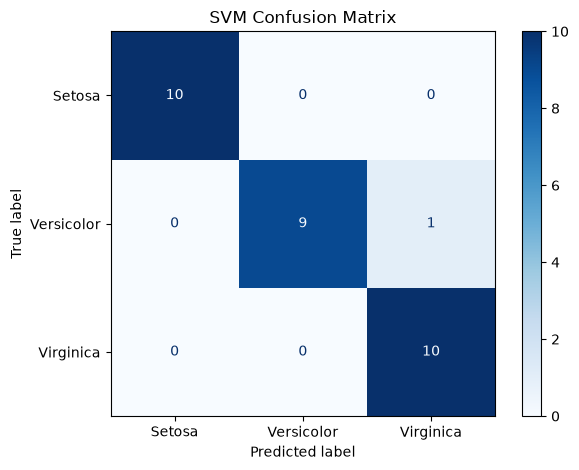

In [5]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

svm_model = models["Support Vector Machine"]
y_pred_svm = svm_model.predict(X_test)

cm = confusion_matrix(y_test, y_pred_svm)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Setosa", "Versicolor", "Virginica"]
)

display.plot(cmap="Blues", values_format="d")
plt.title("SVM Confusion Matrix")
plt.tight_layout()
plt.show()



## Conclusion

The Iris Flower Classification project used four flower measurements to predict three Iris species: Setosa, Versicolor, and Virginica.

The dataset contained 150 samples and had no missing values. Exploratory data analysis showed that petal length and petal width were useful features for distinguishing the species.

Three classification algorithms were compared: Logistic Regression, K-Nearest Neighbors (KNN), and Support Vector Machine (SVM). On the selected 30-sample test set, SVM achieved the highest accuracy of **96.67%**, correctly classifying 29 samples.

The confusion matrix showed that all Setosa and Virginica test samples were classified correctly, while one Versicolor sample was misclassified as Virginica.

Overall, SVM performed best among the three tested models on this split. Further validation, such as stratified cross-validation, could provide a more reliable estimate of its performance on unseen data.